# Does a Trading Tax Calm the Stock Market? An Agent-Based Simulation

**ISCS Final Project: simulation notebook**

The Philippines cut its stock transaction tax from **0.6% to 0.1%** of the selling price on
July 1, 2025 (RA 12214). Real market data cannot isolate the tax's effect, because many other
things changed at the same time. A simulation can hold everything fixed and change only the tax.

This notebook runs every experiment of the project:

| Section | Experiment | Question |
|---|---|---|
| 1 | Single run | What does one simulated market look like? |
| 2 | Common random numbers | How do we compare tax rates fairly? |
| 3 | **E2**: tax × trader mix | H1 (who the tax stops), H2 (does it calm chartist-heavy markets), PH cut effect |
| 4 | **E2b**: tax × market size | H3 (does the tax hurt a thin market) |
| 5 | **E3**: tax with strategy switching | Does herding change the answer? |
| 6 | **E4**: global sensitivity | What drives the size of the PH cut effect? |

The model code lives in the `marketabm` package, which the first cell installs from the
project's GitHub repository. This notebook only sets up the experiments, runs them and shows the results.

> **These results describe the mechanism of a stylized model, not a forecast for the
> Philippine Stock Exchange.**

## 0. Setup

The next cell installs the `marketabm` package from GitHub if it is not already installed
(needs Python 3.12 or newer). On Google Colab, if it asks you to restart the session after
installing, restart and run the notebook again from the top.

In [1]:
import importlib.util

if importlib.util.find_spec("marketabm") is None:
    get_ipython().run_line_magic(
        "pip", "install -q git+https://github.com/Eurie-R/MarketSimulation.git"
    )

In [2]:
%matplotlib inline
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from marketabm import analysis as an
from marketabm import viz
from marketabm.config import ExperimentConfig, ModelConfig, with_overrides
from marketabm.experiments import execute, grid_tasks, sobol_sample, sobol_tasks
from marketabm.market import run
from marketabm.stylized_facts import moments, validation_checks

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

### Run settings

The full design is 2,224 simulations of 50,000 steps each, about **4.5 CPU-hours** in total.
The runs are spread over all CPU cores, so on a 12-core laptop it takes about 25 minutes.
**Colab's free tier has only 2 cores, so the full design takes about 2–3 hours there.**

- `QUICK = True` runs 5 seeds per cell instead of 30, and a smaller Sobol design (about 8× faster).
  The patterns are the same, but the confidence intervals are wider.
- Finished experiments are saved under `results/notebook/`. Re-running the notebook loads them
  instead of simulating again, unless `FORCE_RERUN = True`.

In [3]:
QUICK = False          # True: 5 seeds per cell and a small Sobol design (for a fast test)
FORCE_RERUN = False    # True: ignore saved results and simulate again
N_JOBS = -1            # parallel worker processes (-1 = all cores)

N_SEEDS = 5 if QUICK else 30
SOBOL_BASE_N = 8 if QUICK else 64
SEEDS = {"start": 1000, "count": N_SEEDS}   # every cell uses the same seeds (paired design)
OUT = Path("results/notebook") / ("quick" if QUICK else "full")
FIG_DIR = OUT / "figures"
TAUS = [0.0, 0.001, 0.0025, 0.006, 0.01]    # 0%, 0.1% (new PH rate), 0.25%, 0.6% (old PH rate), 1%
print(f"{N_SEEDS} seeds per cell, {os.cpu_count()} CPU cores, results in {OUT}")

30 seeds per cell, 12 CPU cores, results in results\notebook\full


### The model in brief

- **One stock, traded in a limit order book.** Traders post buy and sell orders; an order that
  crosses the best opposite quote trades at the resting order's price. Price-time priority.
- **1,000 traders, 10 act per step**, chosen at random. A run is 50,000 steps; the first 5,000
  are a burn-in and are excluded from all metrics. Returns are measured over 20-step periods.
- **Three trader types.** Every trader forecasts the price from a weighted mix of three signals:
  - *fundamentalists* expect the price to move back toward the fundamental value;
  - *chartists* (trend-chasers) expect the recent trend to continue;
  - *noise traders* trade on random signals.
- **Where the tax enters.** A trader only acts if the expected price move is larger than the tax
  rate. The tax is paid by the **seller** on every trade, as in the Philippine tax.
- **The fundamental value** follows a random walk that does not depend on trading.

The parameters below are the **calibrated** values. They were chosen in experiment E1 by matching
the shape of the model's returns (fat tails, volatility clustering) to daily returns of the iShares
MSCI Philippines ETF (EPHE). E1 is not re-run here: it is a separate grid search of 1,728 parameter
sets (about 75 minutes on 11 cores). Its result is the six changed values below. No point passed
every validation check, so this is the best compromise (see `docs/results.md`).

In [4]:
# Calibrated parameters from E1; everything else is the package default (configs/baseline.yaml).
CALIBRATED = with_overrides(ModelConfig(), {
    "tau_f": 12.5,             # fundamentalists expect the gap to value to close over ~12.5 steps
    "sigma_eps": 0.0002,       # sd of the per-step noise signal
    "k_max": 0.01,             # max offset of an order's price from the trader's forecast
    "price_band": 0.00875,     # orders priced at most ±0.875% from the last trade
    "vol_feedback": {"enabled": True, "gamma": 3.0},   # noise grows after volatile periods
})

c = CALIBRATED
pd.DataFrame(
    [
        ("steps per run (burn-in)", f"{c.T:,} ({c.T_burn:,})"),
        ("traders N / active per step M", f"{c.N} / {c.M}"),
        ("baseline mix F / C / N", f"{c.mix.fundamentalist:.0%} / {c.mix.chartist:.0%} / {c.mix.noise:.0%}"),
        ("fundamental value volatility per step", c.sigma_f),
        ("order lifetime (steps)", c.order_life),
        ("return period (steps)", c.return_interval),
        ("tau_f, sigma_eps, k_max, price band", f"{c.tau_f}, {c.sigma_eps}, {c.k_max}, {c.price_band}"),
        ("volatility feedback gamma", c.vol_feedback.gamma),
    ],
    columns=["parameter", "value"],
).set_index("parameter")

,value
parameter,
steps per run (burn-in),"50,000 (5,000)"
traders N / active per step M,1000 / 10
baseline mix F / C / N,45% / 25% / 30%
fundamental value volatility per step,0.001
order lifetime (steps),200
return period (steps),20
"tau_f, sigma_eps, k_max, price band","12.5, 0.0002, 0.01, 0.00875"
volatility feedback gamma,3.0


### Helper functions

`run_experiment` expands an experiment's grid into one task per (cell, seed), runs the tasks
in parallel and returns one row of summary metrics per run. `analyze_grid` computes cell means,
paired differences and the PH cut effect, all with 95% t-intervals across seeds.

In [5]:
def run_experiment(exp: ExperimentConfig, base: ModelConfig):
    # Returns (runs table, period returns per run_id, type shares under switching or None).
    out = OUT / exp.name
    files = out / "runs.parquet", out / "returns.parquet", out / "type_shares.parquet"
    if files[0].exists() and not FORCE_RERUN:
        print(f"{exp.name}: loading saved results from {out}")
    else:
        tasks = sobol_tasks(exp) if exp.sobol is not None else grid_tasks(exp)
        print(f"{exp.name}: {len(tasks)} runs")
        t0 = time.perf_counter()
        res = execute(base, tasks, n_jobs=N_JOBS, desc=exp.name)
        runs = pd.DataFrame([r["row"] for r in res])
        runs.insert(0, "run_id", np.arange(len(runs)))
        out.mkdir(parents=True, exist_ok=True)
        runs.to_parquet(files[0], index=False)
        pd.DataFrame({"run_id": runs["run_id"], "R": [r["R"].tolist() for r in res]}).to_parquet(
            files[1], index=False)
        shares = [r["type_shares"].assign(run_id=i) for i, r in enumerate(res) if "type_shares" in r]
        if shares:
            pd.concat(shares, ignore_index=True).to_parquet(files[2], index=False)
        print(f"done in {(time.perf_counter() - t0) / 60:.1f} min")
    runs = pd.read_parquet(files[0])
    ret = pd.read_parquet(files[1])
    returns = {int(i): np.asarray(r, dtype=float) for i, r in zip(ret["run_id"], ret["R"])}
    shares = pd.read_parquet(files[2]) if files[2].exists() else None
    return runs, returns, shares


def analyze_grid(runs, returns, exp):
    # Cell means and PH cut effect for every metric, as in scripts/analyze.py.
    by = [k for k in exp.grid if k != "tau"]
    runs = runs.copy()
    runs["extreme_moves"] = an.extreme_moves(runs, returns, by)
    metrics = [m for m in an.SUMMARY_METRICS if m in runs] + [
        col for col in runs.columns
        if col.startswith(("fills_per_agent_", "skip_rate_tax_", "volume_share_", "share_"))
    ]
    cm = an.cell_means(runs, [*by, "tau"], metrics)
    ph = an.ph_cut_effect(runs, metrics, by)
    return runs, cm, ph


def ci_table(df, index, metrics, digits=3):
    # Wide table of "mean [low, high]" strings, one column per metric.
    d = df[df["metric"].isin(metrics)].copy()
    d["value"] = [f"{m:+.{digits}g} [{lo:+.{digits}g}, {hi:+.{digits}g}]"
                  for m, lo, hi in zip(d["mean"], d["ci_low"], d["ci_high"])]
    return d.pivot(index=index, columns="metric", values="value")[metrics]


def show(fig, name):
    # Save a figure as PNG and PDF, then display it.
    viz.save_figure(fig, FIG_DIR, name)
    plt.show()

## 1. One simulated market

One run at the calibrated parameters with no tax (seed 1000). The market price (blue)
fluctuates around the fundamental value (dashed) without drifting away from it. The burn-in is shaded.

one run of 50,000 steps: 5.9 s


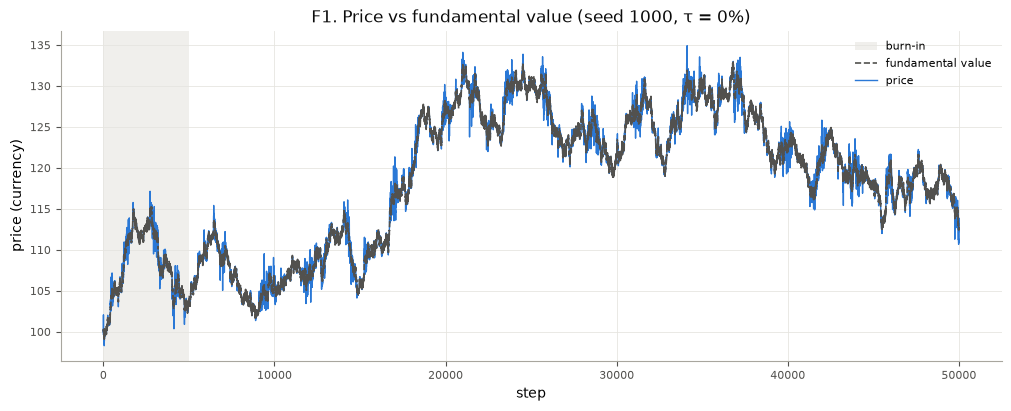

In [6]:
t0 = time.perf_counter()
single = run(CALIBRATED, seed=1000)
print(f"one run of {CALIBRATED.T:,} steps: {time.perf_counter() - t0:.1f} s")
show(viz.fig_price_path(single), "F1_price_path")

The full dashboard for the same run: period returns, who trades, the bid-ask spread, volume, the
return distribution against a normal curve, and the autocorrelation of returns (R) and of their
size (|R|).

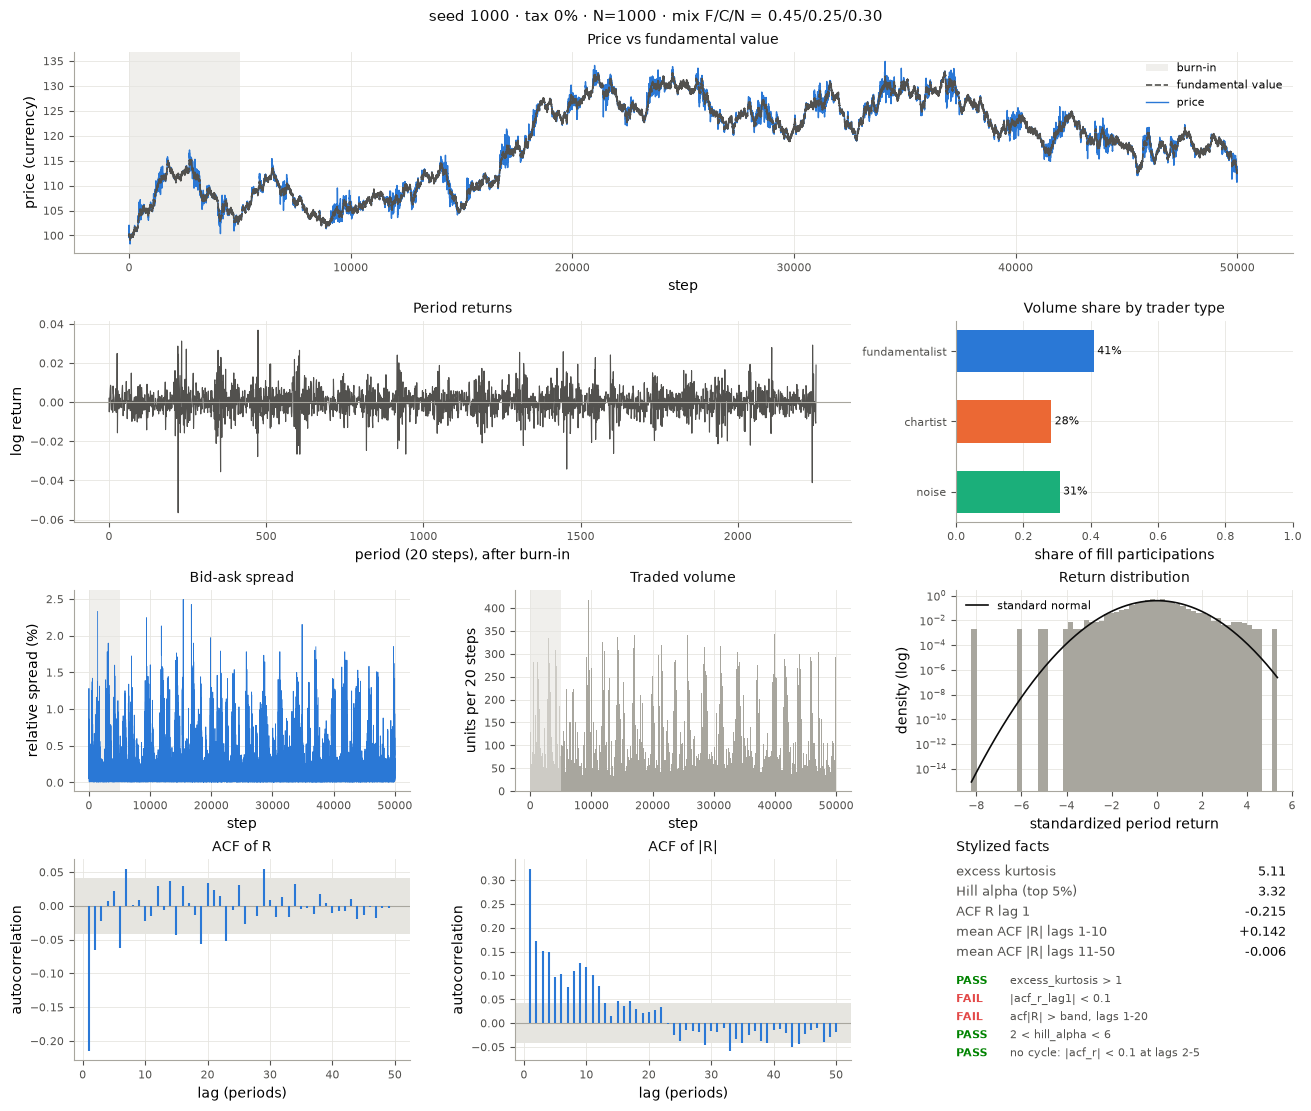

In [7]:
fig = viz.plot_run(single)
plt.show()

### Does the model behave like a real market?

Real returns share a few *stylized facts*: fat tails (crashes more frequent than a bell curve
predicts), volatility clustering (wild periods follow wild periods) and almost no predictability
from one period to the next. Below, the model's returns (this run, standardized) are compared
with daily EPHE returns (2015–2026, 2,986 returns; values from E1).

In [8]:
R = single.period_returns()
m = moments(R)
ephe = {"excess_kurtosis": 38.3, "hill_alpha": 3.22, "acf_r_lag1": -0.10,
        "acf_absr_1_10": 0.20, "acf_absr_11_50": 0.051}
labels = {"excess_kurtosis": "excess kurtosis (fat tails if > 1)",
          "hill_alpha": "Hill tail index (real markets: 2-6)",
          "acf_r_lag1": "autocorrelation of R, lag 1 (target |.| < 0.1)",
          "acf_absr_1_10": "autocorrelation of |R|, lags 1-10 (clustering)",
          "acf_absr_11_50": "autocorrelation of |R|, lags 11-50"}
display(pd.DataFrame({"model (seed 1000)": m, "EPHE": ephe}).rename(index=labels).round(3))
print("Validation checks on this run:")
for name, ok in validation_checks(R).items():
    print(f"  {'PASS' if ok else 'FAIL'}  {name}")

,model (seed 1000),EPHE
excess kurtosis (fat tails if > 1),5.108,38.300
Hill tail index (real markets: 2-6),3.321,3.220
"autocorrelation of R, lag 1 (target |.| < 0.1)",-0.215,-0.100
"autocorrelation of |R|, lags 1-10 (clustering)",0.142,0.200
"autocorrelation of |R|, lags 11-50",-0.006,0.051


Validation checks on this run:
  PASS  excess_kurtosis > 1
  FAIL  |acf_r_lag1| < 0.1
  FAIL  acf|R| > band, lags 1-20
  PASS  2 < hill_alpha < 6
  PASS  no cycle: |acf_r| < 0.1 at lags 2-5


The model reproduces fat tails and a realistic tail index. Volatility clustering is present
but fades faster than in real data, so on this run the |R| autocorrelation drops into the noise
band before lag 20 (averaged over 30 seeds it stays above the band at 16 of 20 lags). The
model also misses one fact: period returns reverse too strongly (lag-1 autocorrelation of about
−0.27 versus −0.10 in EPHE). These are the known limitations of the calibration, reported in
`docs/results.md`.

## 2. Comparing tax rates fairly: common random numbers

Every comparison in this notebook is **paired by seed**. A seed fixes every random number in a
run: the fundamental value path, the traders' parameters, who acts at each step and the noise
signals. Running the same seed at two tax rates therefore changes **only the tax**, so any
difference between the two runs is caused by it.

Below: seed 1000 at the old (0.6%) and new (0.1%) Philippine rates.

Same fundamental path and same traders in both runs; only the tax differs.


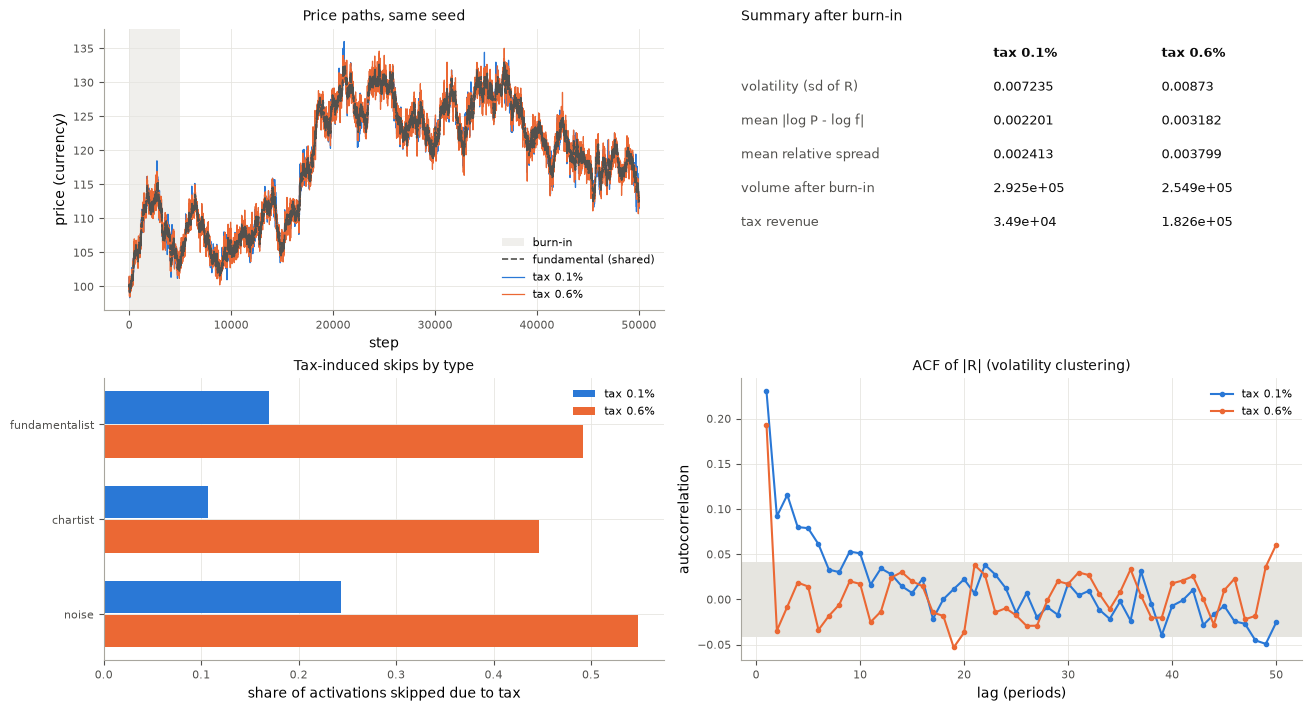

In [9]:
old = run(with_overrides(CALIBRATED, {"tau": 0.006}), seed=1000)
new = run(with_overrides(CALIBRATED, {"tau": 0.001}), seed=1000)
assert np.array_equal(old.fundamental, new.fundamental)
assert all(np.array_equal(old.agent_params[k], new.agent_params[k]) for k in old.agent_params)
print("Same fundamental path and same traders in both runs; only the tax differs.")
fig = viz.plot_compare(new, old)
plt.show()

## 3. E2: tax rate × share of chartists

**Design:** 5 tax rates × 4 chartist shares (10%, 25%, 40%, 55%) × 30 seeds = **600 runs**.
When the chartist share changes, fundamentalists and noise traders keep their 60 : 40 ratio.

**Hypotheses**
- **H1:** the tax cuts chartist and noise trading more than fundamentalist trading.
- **H2:** in chartist-heavy markets (40%, 55%), a higher tax lowers volatility and mispricing.

**Headline quantity, the "PH cut effect":** the per-seed difference
`metric(τ = 0.1%) − metric(τ = 0.6%)`, i.e. what the model says the 2025 cut did.
A negative value means the cut lowered the metric.

In [10]:
E2 = ExperimentConfig(
    name="e2_tax_mix", base="calibrated", seeds=SEEDS,
    grid={"tau": TAUS, "chartist_share": [0.10, 0.25, 0.40, 0.55]},
)
e2_runs, e2_returns, _ = run_experiment(E2, CALIBRATED)
e2_runs, e2_cm, e2_ph = analyze_grid(e2_runs, e2_returns, E2)

e2_tax_mix: loading saved results from results\notebook\full\e2_tax_mix


### Cell means (F3)

Each square is the mean over seeds for one (tax, chartist share) cell. Volatility is the standard
deviation of 20-step log returns; mispricing is the mean distance between log price and log
fundamental value.

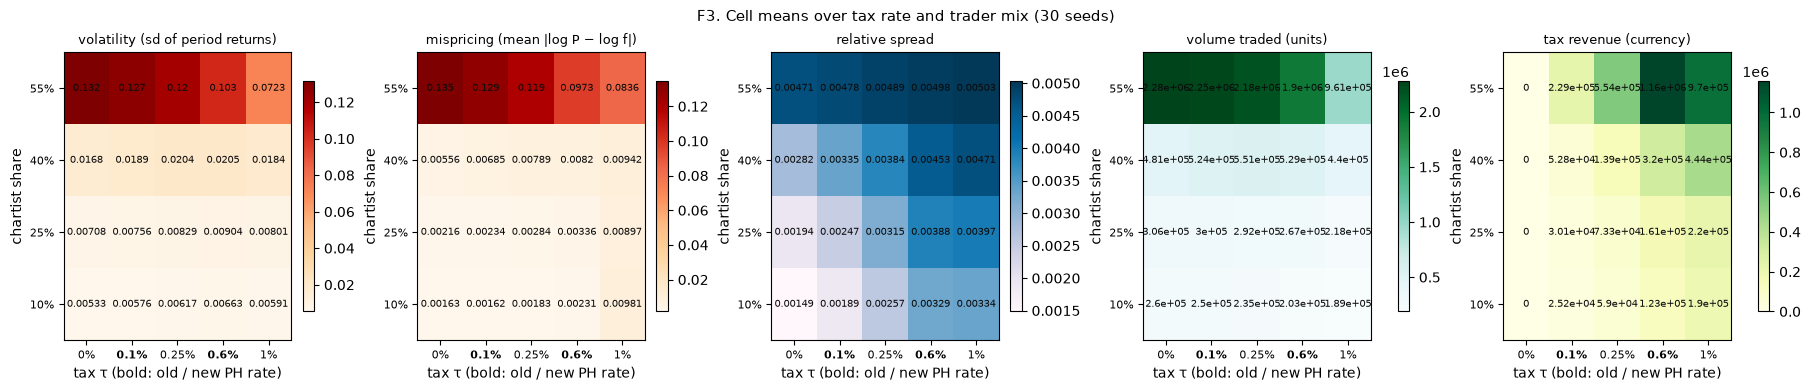

In [11]:
show(viz.fig_heatmaps(e2_cm, ["vol", "mispricing", "rel_spread_mean", "volume_total", "tax_revenue"]),
     "F3_heatmaps")

### Volatility relative to no tax

The same volatility means, rescaled so that each chartist share's no-tax value is 100.
A value of 124 means volatility is 24% higher than in the same market with no tax.
Because each line has its own baseline, compare the **direction** of the lines, not their levels:
the 55% market is about 20 times more volatile than the 25% market in absolute terms.

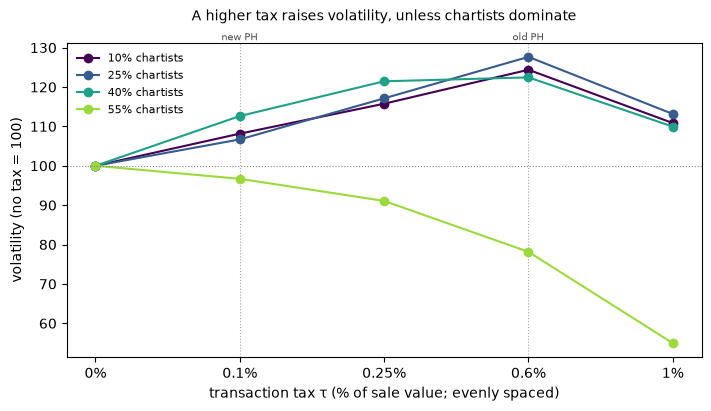

chartist_share,10% chartists,25% chartists,40% chartists,55% chartists
tau,,,,
0%,100.0,100.0,100.0,100.0
0.1%,108.0,107.0,113.0,97.0
0.25%,116.0,117.0,121.0,91.0
0.6%,124.0,128.0,122.0,78.0
1%,111.0,113.0,110.0,55.0


In [12]:
v = e2_cm[e2_cm["metric"] == "vol"].pivot(index="tau", columns="chartist_share", values="mean")
idx = 100 * v / v.loc[0.0]
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
colors = plt.get_cmap("viridis")(np.linspace(0, 0.85, idx.shape[1]))
for color, share in zip(colors, idx.columns):
    ax.plot(range(len(idx)), idx[share], "o-", color=color, label=f"{share:.0%} chartists")
ax.axhline(100, color="grey", lw=0.8, ls=":")
viz._tau_axis(ax, list(idx.index))
ax.set_ylabel("volatility (no tax = 100)")
ax.legend(frameon=False, fontsize=8)
ax.set_title("A higher tax raises volatility, unless chartists dominate", fontsize=10, pad=16)
show(fig, "volatility_index")
idx.round(0).rename(index=viz.pct).rename(columns=lambda s: f"{s:.0%} chartists")

### The PH cut effect (F4)

Mean and 95% paired confidence interval of `metric(0.1%) − metric(0.6%)` for each chartist share.
Red: the cut raises the metric (CI above 0). Green: the cut lowers it (CI below 0).

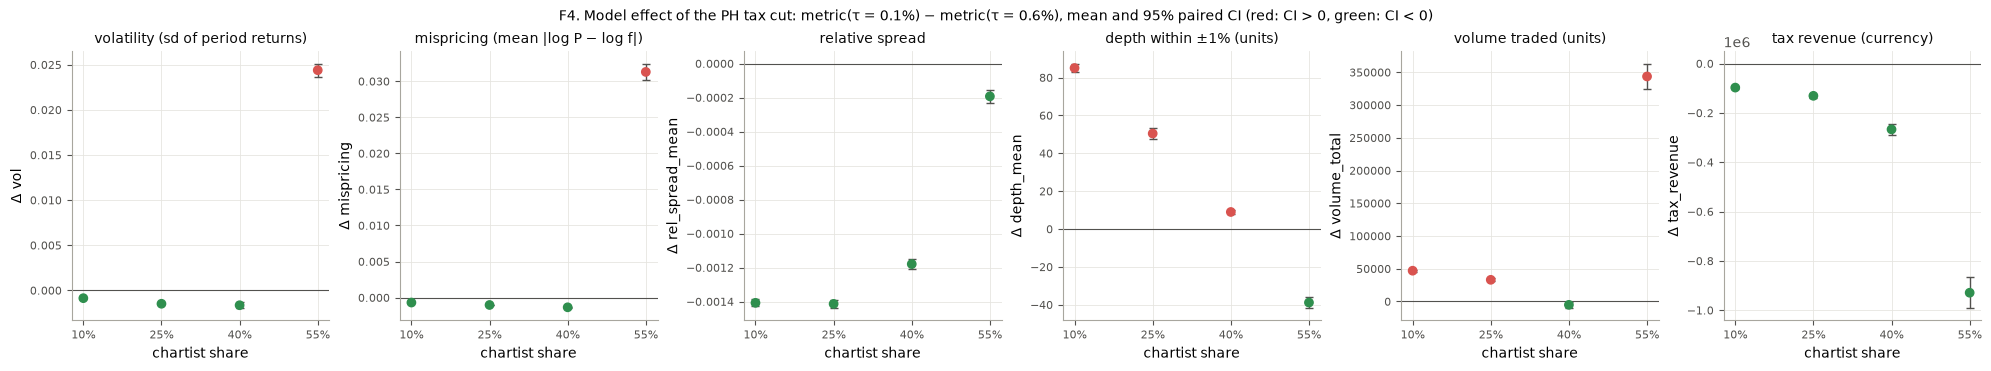

metric,vol,mispricing,rel_spread_mean,depth_mean,tax_revenue
chartist_share,,,,,
0.10,"-0.000864 [-0.000918, -0.000811]","-0.000685 [-0.000703, -0.000667]","-0.00141 [-0.00143, -0.00139]","+85.1 [+82.7, +87.4]","-9.74e+04 [-1.04e+05, -9.1e+04]"
0.25,"-0.00148 [-0.00156, -0.00141]","-0.00102 [-0.00105, -0.00099]","-0.00141 [-0.00144, -0.00139]","+50.4 [+47.6, +53.3]","-1.31e+05 [-1.4e+05, -1.22e+05]"
0.40,"-0.00165 [-0.00196, -0.00133]","-0.00134 [-0.00145, -0.00124]","-0.00118 [-0.00121, -0.00115]","+9 [+7.75, +10.2]","-2.67e+05 [-2.89e+05, -2.45e+05]"
0.55,"+0.0244 [+0.0237, +0.0251]","+0.0313 [+0.0301, +0.0325]","-0.000193 [-0.00023, -0.000156]","-38.9 [-41.8, -36]","-9.29e+05 [-9.91e+05, -8.67e+05]"


In [13]:
show(viz.fig_ph_cut(e2_ph, ["vol", "mispricing", "rel_spread_mean", "depth_mean",
                            "volume_total", "tax_revenue"]), "F4_ph_cut_effect")
ci_table(e2_ph, "chartist_share", ["vol", "mispricing", "rel_spread_mean", "depth_mean", "tax_revenue"])

### H1: who does the tax stop? (F5)

Share of each type's activations in which the trader wanted to trade but the expected gain did
not cover the tax.

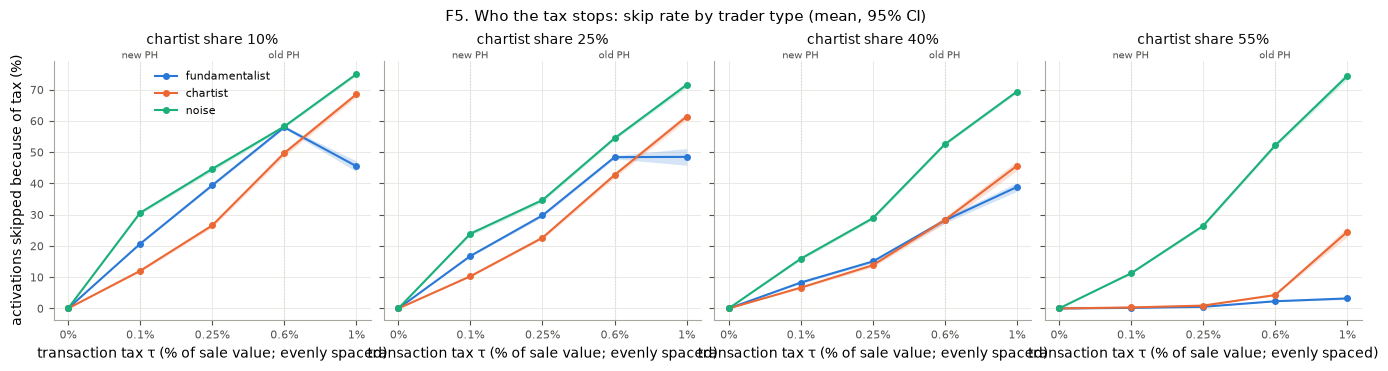

In [14]:
show(viz.fig_skip_rates(e2_cm), "F5_skip_rates")

### Hypothesis checks H1 and H2

The verdicts below come from the paired confidence intervals, applied as defined in the
project plan:
- **H1** holds in a cell if the drop in fills per agent (relative to τ = 0) is larger for both
  chartists and noise traders than for fundamentalists, with non-overlapping 95% CIs.
- **H2** holds at a chartist share if, for some τ > 0, both Δ volatility and Δ mispricing
  have CIs entirely below 0.

No correction for multiple comparisons is applied; the number of intervals inspected is given with each verdict.

In [15]:
display(Markdown(an.hypotheses_markdown([an.check_h1(e2_runs, ["chartist_share"]),
                                         an.check_h2(e2_runs)], "E2")))

# Hypothesis checks: E2

Results describe the model's mechanism, not a forecast for the PSE. Each verdict lists how many confidence intervals it rests on; no correction for multiple comparisons is applied.

## H1: mixed

Number of comparisons (CIs inspected): 32.

Relative change in fills per agent vs τ = 0 (mean [95% CI], paired by seed). H1 holds in 8 of 16 cells.

| chartist_share, tau | fundamentalist | chartist | noise | H1 holds |
|---|---|---|---|---|
| 0.1, 0.001 | -0.1104 [-0.1146, -0.1062] | +0.01149 [+0.007095, +0.01589] | -0.0646 [-0.07522, -0.05397] | no |
| 0.25, 0.001 | -0.03861 [-0.0449, -0.03233] | +0.02714 [+0.02394, +0.03034] | -0.06468 [-0.07055, -0.05882] | no |
| 0.4, 0.001 | +0.05169 [+0.04793, +0.05545] | +0.02388 [+0.01884, +0.02892] | -0.104 [-0.1068, -0.1011] | yes |
| 0.55, 0.001 | -0.007885 [-0.00936, -0.006409] | -0.009835 [-0.01104, -0.008636] | -0.09386 [-0.0964, -0.09133] | no |
| 0.1, 0.0025 | -0.1972 [-0.2055, -0.1889] | -0.02236 [-0.03212, -0.0126] | -0.104 [-0.1137, -0.09431] | no |
| 0.25, 0.0025 | -0.04358 [-0.05199, -0.03517] | -0.01336 [-0.01944, -0.007281] | -0.1491 [-0.1551, -0.1432] | no |
| 0.4, 0.0025 | +0.05526 [+0.048, +0.06253] | -0.01714 [-0.02482, -0.009464] | -0.2295 [-0.2328, -0.2262] | yes |
| 0.55, 0.0025 | -0.01971 [-0.02122, -0.01819] | -0.02541 [-0.0268, -0.02402] | -0.2302 [-0.2352, -0.2252] | yes |
| 0.1, 0.006 | -0.3362 [-0.343, -0.3294] | -0.2721 [-0.2846, -0.2597] | -0.2881 [-0.2961, -0.28] | no |
| 0.25, 0.006 | -0.199 [-0.2059, -0.1921] | -0.2215 [-0.2303, -0.2128] | -0.3801 [-0.3864, -0.3738] | yes |
| 0.4, 0.006 | -0.07189 [-0.07971, -0.06407] | -0.1648 [-0.1739, -0.1557] | -0.4609 [-0.4649, -0.457] | yes |
| 0.55, 0.006 | -0.08779 [-0.09582, -0.07977] | -0.1067 [-0.1153, -0.09816] | -0.478 [-0.4841, -0.472] | yes |
| 0.1, 0.01 | -0.5743 [-0.585, -0.5635] | -0.6761 [-0.6891, -0.6631] | -0.5006 [-0.5102, -0.4911] | no |
| 0.25, 0.01 | -0.507 [-0.5241, -0.49] | -0.5746 [-0.5969, -0.5524] | -0.5533 [-0.5626, -0.5439] | yes |
| 0.4, 0.01 | -0.3187 [-0.3402, -0.2972] | -0.4007 [-0.4229, -0.3785] | -0.6191 [-0.6235, -0.6147] | yes |
| 0.55, 0.01 | -0.5463 [-0.5688, -0.5237] | -0.5694 [-0.5902, -0.5487] | -0.6917 [-0.7044, -0.6791] | no |

## H2: mixed

Number of comparisons (CIs inspected): 16.

Paired differences vs τ = 0 (mean [95% CI]).

| chartist share | τ | Δ vol | Δ mispricing |
|---|---|---|---|
| 0.40 | 0.001 | +0.002118 [+0.001843, +0.002393] | +0.00129 [+0.00121, +0.001371] |
| 0.40 | 0.0025 | +0.003598 [+0.003278, +0.003919] | +0.002329 [+0.00222, +0.002439] |
| 0.40 | 0.006 | +0.003765 [+0.003394, +0.004135] | +0.002635 [+0.002505, +0.002765] |
| 0.40 | 0.01 | +0.001667 [+0.001222, +0.002113] | +0.003859 [+0.003038, +0.004681] |
| 0.55 | 0.001 | -0.004353 [-0.00473, -0.003977] | -0.005907 [-0.006452, -0.005362] |
| 0.55 | 0.0025 | -0.01174 [-0.01226, -0.01122] | -0.01547 [-0.01624, -0.01471] |
| 0.55 | 0.006 | -0.02875 [-0.02958, -0.02791] | -0.0372 [-0.03845, -0.03595] |
| 0.55 | 0.01 | -0.05926 [-0.06103, -0.05749] | -0.05091 [-0.05519, -0.04663] |


## 4. E2b: tax rate × market size

**Design:** 5 tax rates × N ∈ {250, 1,000} traders × 30 seeds = **300 runs**, baseline mix
(45% fundamentalists, 25% chartists, 30% noise). Ten traders act per step in both markets, so
"thin" means fewer distinct traders and fewer resting orders.

**H3:** in a thin market (N = 250), a higher tax raises volatility through larger price impact,
alongside a wider spread and less depth.

e2b_thin_market: loading saved results from results\notebook\full\e2b_thin_market


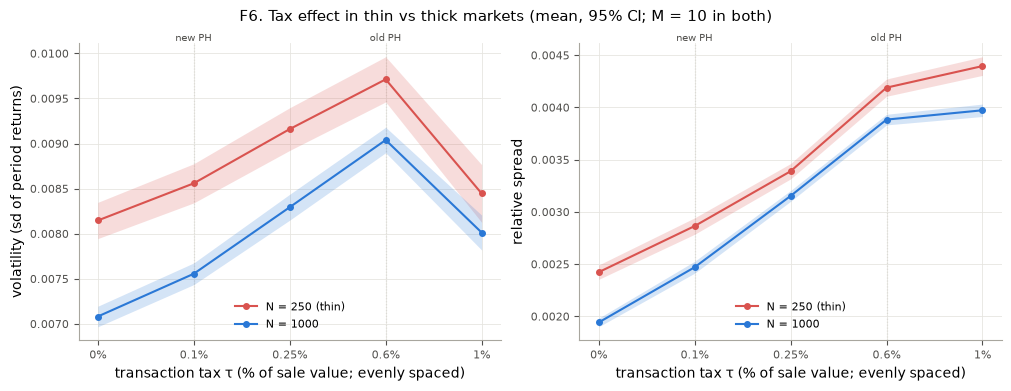

# Hypothesis checks: E2b

Results describe the model's mechanism, not a forecast for the PSE. Each verdict lists how many confidence intervals it rests on; no correction for multiple comparisons is applied.

## H3: supported

Number of comparisons (CIs inspected): 12.

N = 250: paired differences vs τ = 0 (mean [95% CI]).

| τ | Δ vol | Δ rel. spread | Δ depth |
|---|---|---|---|
| 0.001 | +0.0004122 [+0.0003104, +0.0005141] | +0.0004415 [+0.000421, +0.000462] | -20.47 [-21.41, -19.54] |
| 0.0025 | +0.001014 [+0.0008919, +0.001136] | +0.0009663 [+0.0009334, +0.0009993] | -34.05 [-36.05, -32.05] |
| 0.006 | +0.001566 [+0.001445, +0.001687] | +0.001767 [+0.001713, +0.00182] | -36.83 [-39.19, -34.47] |
| 0.01 | +0.0002995 [+0.0001225, +0.0004764] | +0.001973 [+0.001915, +0.002031] | -27.22 [-29.38, -25.05] |


PH cut effect, metric(0.1%) - metric(0.6%):


metric,vol,mispricing,rel_spread_mean,depth_mean
N,,,,
250,"-0.00115 [-0.00123, -0.00107]","-0.000889 [-0.000922, -0.000856]","-0.00133 [-0.00137, -0.00128]","+16.4 [+14.8, +17.9]"
1000,"-0.00148 [-0.00156, -0.00141]","-0.00102 [-0.00105, -0.00099]","-0.00141 [-0.00144, -0.00139]","+50.4 [+47.6, +53.3]"


In [16]:
E2B = ExperimentConfig(
    name="e2b_thin_market", base="calibrated", seeds=SEEDS,
    grid={"tau": TAUS, "N": [250, 1000]}, overrides={"M": 10},
)
e2b_runs, e2b_returns, _ = run_experiment(E2B, with_overrides(CALIBRATED, E2B.overrides))
e2b_runs, e2b_cm, e2b_ph = analyze_grid(e2b_runs, e2b_returns, E2B)
show(viz.fig_thin_market(e2b_cm), "F6_thin_market")
display(Markdown(an.hypotheses_markdown([an.check_h3(e2b_runs)], "E2b")))
print("PH cut effect, metric(0.1%) - metric(0.6%):")
ci_table(e2b_ph, "N", ["vol", "mispricing", "rel_spread_mean", "depth_mean"])

## 5. E3: tax with strategy switching

In E2 every trader keeps its type. Here, every 500 steps each non-noise trader re-chooses between
the fundamentalist and chartist strategies. The choice is a logit of the profit each strategy
earned in the last window (Brock & Hommes 1998). The *intensity of choice* β sets how strongly
traders chase the better strategy: β = 2 is mild, β = 15 is strong (herding).

**Design:** 5 tax rates × β ∈ {2, 15} × 30 seeds = **300 runs**, starting from the baseline mix.

e3_adaptive: loading saved results from results\notebook\full\e3_adaptive


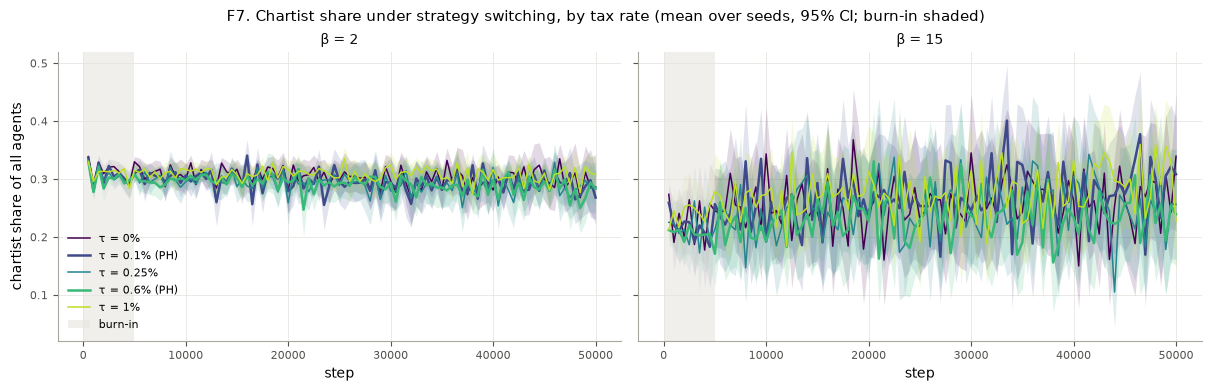

In [17]:
E3 = ExperimentConfig(
    name="e3_adaptive", base="calibrated", seeds=SEEDS,
    grid={"tau": TAUS, "beta": [2.0, 15.0]}, overrides={"switching": {"S": 500}},
)
e3_runs, e3_returns, e3_shares = run_experiment(E3, with_overrides(CALIBRATED, E3.overrides))
e3_runs, e3_cm, e3_ph = analyze_grid(e3_runs, e3_returns, E3)
show(viz.fig_switching(e3_shares, e3_runs, CALIBRATED.T_burn), "F7_switching")

In [18]:
summary = e3_cm[e3_cm["metric"].isin(["vol", "share_mean_chartist", "share_sd_chartist"])
                & e3_cm["tau"].isin([0.0, 0.01])]
display(summary.pivot(index=["beta", "tau"], columns="metric", values="mean").round(4)
        .rename(columns={"share_mean_chartist": "mean chartist share",
                         "share_sd_chartist": "swing sd of chartist share"}))
print("PH cut effect, metric(0.1%) - metric(0.6%):")
ci_table(e3_ph, "beta", ["vol", "mispricing", "rel_spread_mean"])

metric     mean chartist share  swing sd of chartist share     vol
beta tau                                                          
2.0  0.00               0.3025                      0.0842  0.0219
     0.01               0.3081                      0.0611  0.0150
15.0 0.00               0.2589                      0.2554  0.0894
     0.01               0.2753                      0.2061  0.0467

PH cut effect, metric(0.1%) - metric(0.6%):


metric,vol,mispricing,rel_spread_mean
beta,,,
2.0,"+0.00326 [-0.00109, +0.00762]","+0.000487 [-0.00157, +0.00255]","-0.00136 [-0.00139, -0.00134]"
15.0,"+0.021 [+0.0162, +0.0258]","+0.0391 [+0.0287, +0.0495]","-0.0011 [-0.00115, -0.00105]"


## 6. E4: what drives the size of the PH cut effect?

A global sensitivity analysis (Sobol indices). Three parameters vary together over wide ranges:
the number of traders N ∈ [250, 2000], the order lifetime ∈ [50, 500] steps, and the volatility
of the fundamental value σ_f ∈ [0.0005, 0.002]. At each of 512 sample points (Saltelli design,
base 64), the same seed is run at 0.6% and at 0.1%. The output is the PH cut effect at that point.

- **S1** (first order): share of the output's variance explained by the parameter alone.
- **ST** (total): the same, including interactions with the other parameters.

e4_sensitivity: loading saved results from results\notebook\full\e4_sensitivity


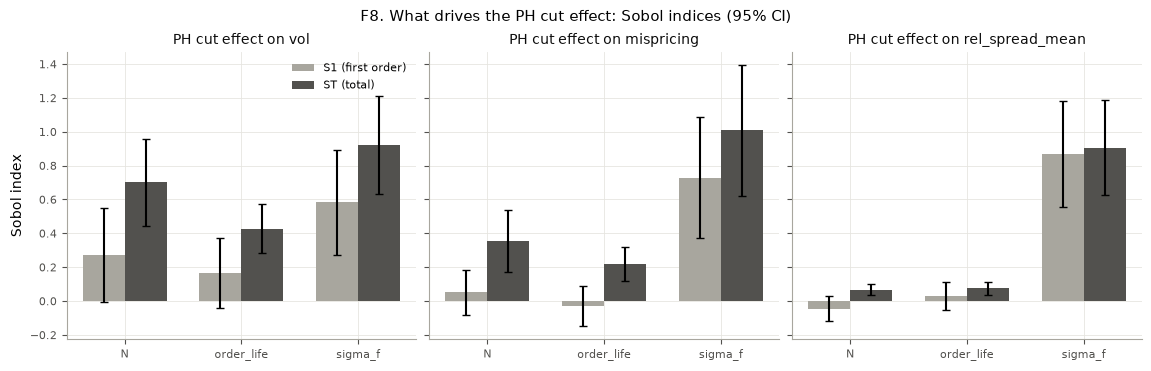

S1                               ST                      
output     mispricing rel_spread_mean   vol mispricing rel_spread_mean   vol
param                                                                       
N                0.05           -0.05  0.27       0.35            0.07  0.70
order_life      -0.03            0.03  0.16       0.22            0.07  0.43
sigma_f          0.73            0.87  0.58       1.01            0.91  0.92

In [19]:
E4 = ExperimentConfig(
    name="e4_sensitivity", base="calibrated",
    sobol={"params": {"N": [250, 2000], "order_life": [50, 500], "sigma_f": [0.0005, 0.002]},
           "integer_params": ["N", "order_life"], "base_n": SOBOL_BASE_N,
           "calc_second_order": True, "seed_start": 5000, "taus": [0.006, 0.001],
           "outputs": ["vol", "mispricing", "rel_spread_mean"], "sample_seed": 0},
)
e4_runs, _, _ = run_experiment(E4, CALIBRATED)
problem, _ = sobol_sample(E4)
e4_y = an.sobol_outputs(e4_runs, E4.sobol.outputs)
e4_idx = an.sobol_indices(e4_y, problem, E4.sobol.calc_second_order)
show(viz.fig_sobol(e4_idx), "F8_sobol")
e4_idx.pivot(index="param", columns="output", values=["S1", "ST"]).round(2)

## 7. Conclusions

The numbers below are from the full run (30 seeds per cell).

**The tax's effect depends on who trades.** Prior work describes two opposing effects, and the model shows both:
- **Liquidity effect (10–40% chartists).** The tax scares off traders, mostly noise traders,
  and thins the order book. Each order then moves the price more, so a higher tax **raises**
  volatility, spreads and mispricing. Here the 0.6% → 0.1% cut makes the market calmer
  (volatility about 8–17% lower) and cheaper to trade in.
- **Composition effect (55% chartists).** The market swings through booms and busts. The tax
  blocks trend-chasing trades and calms it. Here the cut **raises** volatility (+24%) and mispricing.

**Hypotheses**
- **H1, mixed.** The tax mainly filters out noise traders. Whether chartists or fundamentalists
  lose more depends on the mix.
- **H2, mixed.** A higher tax calms the market at 55% chartists but not at 40%.
- **H3, supported.** In the thin market the tax raises volatility and spreads and lowers depth.
  The thick market shows the same pattern, so thinness does not create a separate effect.

**Switching (E3).** Letting traders switch strategies makes the market more volatile. With strong
switching (herding), the cut raises volatility and mispricing, as in the chartist-dominated regime.

**Sensitivity (E4).** The size of the PH cut effect is driven mainly by the volatility of the
fundamental value σ_f.

**What this means for the Philippine cut.** In this model the cut helps while trend-chasing on
the exchange stays limited. The risk is herding, where the effect flips. The cut lowered tax
revenue in every simulated market. These are properties of a stylized model, not a forecast for
the PSE.